 `HistoryOfBacklogs` 1 = has had backlog, 0 = no backlog. `PlacedOrNot` 1 = placed, 0 = not placed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("placements.csv")
overall = df["PlacedOrNot"].mean() * 100
print("Students:", len(df))
print(f"Overall placement: {overall:.2f}%")
df.head()

Students: 2966
Overall placement: 55.26%


,Age,Gender,Stream,Internships,CGPA,Hostel,HistoryOfBacklogs,PlacedOrNot
0,22,Male,Electronics And Communication,1,8,1,1,1
1,21,Female,Computer Science,0,7,1,1,1
2,22,Female,Information Technology,1,6,0,0,1
3,21,Male,Information Technology,0,8,0,1,1
4,22,Male,Mechanical,0,8,1,0,1


## 1. Summary tables

In [2]:
def summarise(data, col):
    t = data.groupby(col)["PlacedOrNot"].agg(Total_Students="count", Placed="sum")
    t["Not_Placed"] = t["Total_Students"] - t["Placed"]
    t["Placement_%"] = (t["Placed"] / t["Total_Students"] * 100).round(2)
    return t.sort_values("Placement_%", ascending=False)

streams = summarise(df, "Stream")
backlog = summarise(df, "HistoryOfBacklogs")
backlog.index = backlog.index.map({0: "No backlog history", 1: "Has backlog history"})

streams.to_csv("stream_summary.csv")
backlog.to_csv("backlog_summary.csv")
streams

,Total_Students,Placed,Not_Placed,Placement_%
Stream,,,,
Electronics And Communication,424,251,173,59.20
Information Technology,691,409,282,59.19
Computer Science,776,452,324,58.25
Electrical,334,181,153,54.19
Mechanical,424,200,224,47.17
Civil,317,146,171,46.06


In [3]:
backlog

,Total_Students,Placed,Not_Placed,Placement_%
HistoryOfBacklogs,,,,
No backlog history,2396,1337,1059,55.80
Has backlog history,570,302,268,52.98


## 2. Graphs

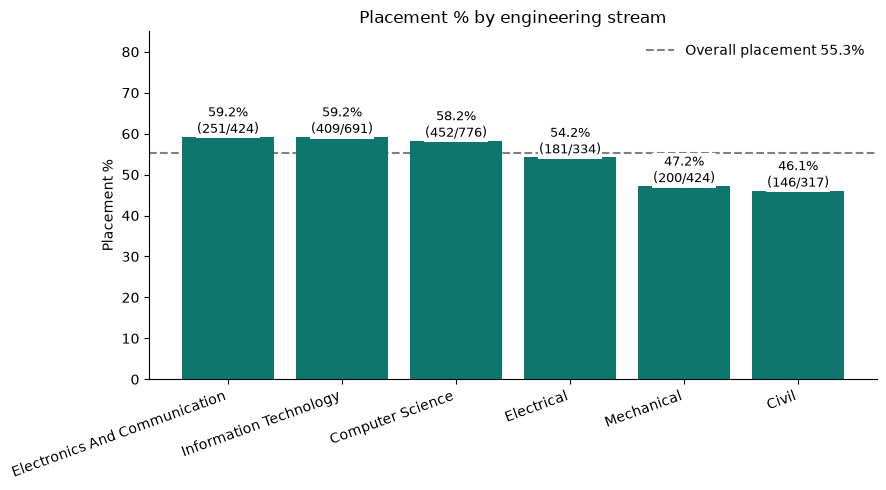

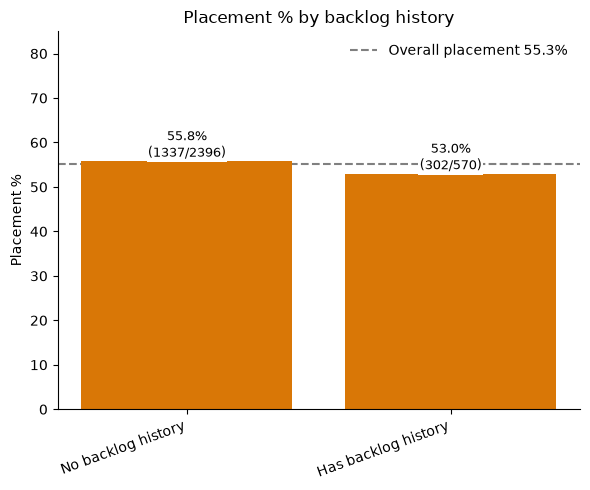

In [4]:
def bar(t, title, fname, color, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(t.index, t["Placement_%"], color=color)
    ax.axhline(overall, ls="--", color="grey", zorder=0, label=f"Overall placement {overall:.1f}%")
    ax.legend(frameon=False, loc="upper right")
    for b, (_, r) in zip(bars, t.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1,
                f"{r['Placed']/r['Total_Students']*100:.1f}%\n({int(r['Placed'])}/{int(r['Total_Students'])})",
                ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_ylim(0, 85); ax.set_ylabel("Placement %"); ax.set_title(title)
    plt.xticks(rotation=20, ha="right")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

bar(streams, "Placement % by engineering stream", "stream_placement.png", "#0F766E", (9, 5))
bar(backlog, "Placement % by backlog history", "backlog_placement.png", "#D97706", (6, 5))

## 3. the dataset has many repeated rows
The same comparisons using unique rows only.

In [5]:
uniq = df.drop_duplicates()
print("Rows:", len(df), "| unique rows:", len(uniq))
pd.concat({"Stream (unique rows)": summarise(uniq, "Stream")["Placement_%"]}, axis=1)

Rows: 2966 | unique rows: 1137


,Stream (unique rows)
Stream,
Information Technology,62.96
Computer Science,62.14
Electronics And Communication,60.34
Electrical,54.37
Mechanical,51.52
Civil,51.32


In [6]:
summarise(uniq, "HistoryOfBacklogs")[["Total_Students", "Placed", "Placement_%"]]

,Total_Students,Placed,Placement_%
HistoryOfBacklogs,,,
0,800,478,59.75
1,337,181,53.71


## 4. Conclusion 
- Electronics and Communication, Information Technology and Computer Science have the highest placement (about 58 to 59%). Mechanical (47.2%) and Civil (46.1%) are lowest, a gap of about 13 points between best and worst stream.
- Students with no backlog history are placed at 55.8% and those with backlog history at 53.0%, a difference of only about 3 points.
- The same pattern holds when repeated rows are removed.

**Limitations:** these are patterns in one dataset, not proof that stream or backlog history causes placement. About 62% of rows are repeats, and backlog groups are unequal in size (2,396 vs 570).